In [40]:
from langgraph.graph import StateGraph,START,END

In [41]:
from typing import TypedDict,Annotated,Literal

In [42]:
class runstate(TypedDict):
    run : int
    balls : int
    fours : int
    sixes : int

    sr : float
    bpb : float
    bp : float

    summary : str

In [43]:
graph = StateGraph(runstate)

In [44]:
def calculate_sr(state : runstate):
    runs = state['run']
    balls = state['balls']
    sr = (runs/balls)*100
    return {'sr' : sr}

In [45]:
def calculate_bpb(state : runstate):
    sixes = state['sixes']
    fours = state['fours']
    balls = state['balls']
    b = sixes+fours
    bpb = (b/balls)*100
    return {'bpb' : bpb}

In [46]:
def calculate_bp(state : runstate):
    s = state['sixes']*6
    f = state['fours']*4
    r = state['run']
    bp = ((s+f)/r)*100
    return {'bp' : bp}

In [47]:
graph.add_node('calculate_sr',calculate_sr)
graph.add_node('calculate_bpb',calculate_bpb)
graph.add_node('calculate_bp',calculate_bp)

In [48]:
from langchain_google_genai import ChatGoogleGenerativeAI
from langchain_core.prompts import ChatPromptTemplate,MessagesPlaceholder
from dotenv import load_dotenv
load_dotenv()

True

In [49]:
model = ChatGoogleGenerativeAI(model='gemini-2.5-flash')

In [50]:
prompt = ChatPromptTemplate([
    ('system','you are an cricket report generator and you have to generate a detailed report on the basis of a state that is going to provided'),
    ('human','{stats}')
])

In [51]:
from langchain_core.output_parsers import StrOutputParser
parser = StrOutputParser()

In [52]:
chain = prompt | model | parser

In [53]:
def summary_gen(state : runstate):
    stats = {
        'run' : state['run'],
        'balls' : state['balls'],
        'fours' : state['fours'],
        'sixes' : state['sixes'],
        'sr' : state['sr'],
        'bpb' : state['bpb'],
        'bp' : state['bp']
    }
    stats = str(stats)
    result = chain.invoke({
        'stats' : stats
    })
    return {'summary' : result}

In [54]:
graph.add_node('summary_gen',summary_gen)

In [55]:
graph.add_edge(START,'calculate_sr')
graph.add_edge(START,'calculate_bpb')
graph.add_edge(START,'calculate_bp')
graph.add_edge('calculate_bp','summary_gen')
graph.add_edge('calculate_bpb','summary_gen')
graph.add_edge('calculate_sr','summary_gen')
graph.add_edge('summary_gen',END)

In [56]:
workflow = graph.compile()

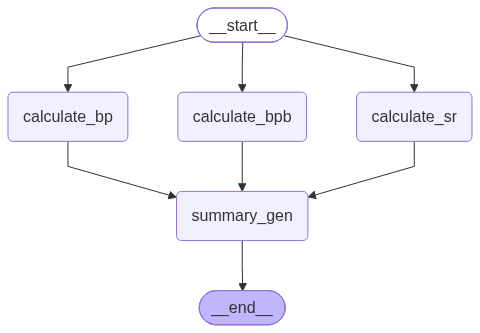

In [57]:
workflow

In [58]:
initial ={
    'run' :157,
    'balls' : 70,
    'fours' : 14,
    'sixes' : 10
}

In [60]:
final_state = workflow.invoke(initial)

In [61]:
print(final_state['summary'])

Here's a detailed report based on the provided statistics, painting a vivid picture of a truly extraordinary innings:

---

## **Spectacular 157-Run Blitz: A Masterclass in Aggression Lights Up The Stadium**

In an innings that will undoubtedly be etched into the annals of cricket history, a sensational batting performance saw a player unleash an unforgettable blitz, smashing an astounding **157 runs off just 70 deliveries**. This wasn't just a knock; it was a statement, a masterclass in modern power-hitting that left spectators in awe and the opposition in disarray.

The cornerstone of this monumental effort was the astonishing run tally of 157, achieved with breathtaking speed. Facing a mere 70 balls, the batter demonstrated an incredible ability to find gaps and clear the ropes at will, turning what could have been a challenging total into a commanding one (or chasing down a daunting target with remarkable ease). The sheer volume of runs in such a short timeframe speaks volumes abou